In [2]:
from pathlib import Path

import numpy as np
import pandas as pd

data_path = Path("used_cars_cleaned_08.csv")
df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn types:")
display(df.dtypes.to_frame("Data type"))

print("\nMissing values per column (largest first):")
display(
    df.isna().sum()
      .sort_values(ascending=False)
      .to_frame("Missing values")
      .head(15)
)

print("\nTarget price summary:")
display(df["price_gbp"].describe().to_frame("price_gbp"))

print("\nTarget-derived columns to exclude from model inputs:")
print([col for col in ["log_price"] if col in df.columns])


Dataset shape: (361590, 33)

First five rows:


,make,model,version,price_gbp,mileage_miles,reg_year,fuel,transmission,power_hp,body_type,...,mileage_imputed,power_hp_imputed,co2_imputed,previous_owners_imputed,log_price,miles_per_year,engine_size_l,is_performance_trim,is_high_value,is_classic
0,Volkswagen,Polo,1.0 EVO Life Euro 6 (s/s) 5dr,13590,27685,2022,Petrol,Manual,79,Hatchback,...,0,0,0,0,9.517163,6921.2,1.0,0,0,0
1,BMW,X5,3.0d Sport Auto 4WD Euro 4 5dr,995,119000,2003,Diesel,Automatic,181,SUV,...,0,0,0,0,6.903747,5173.9,3.0,0,0,0
2,Audi,S3,2.0 TFSI Sportback S Tronic quattro Euro 6 (s/...,16490,70000,2016,Petrol,Automatic,306,Hatchback,...,0,0,0,0,9.710570,7000.0,2.0,0,0,0
3,Volvo,XC40,2.0 B3 MHEV Plus Black Edition DCT Auto Euro 6...,31250,4767,2026,Petrol Hybrid,Automatic,161,SUV,...,0,0,0,0,10.349807,4767.0,2.0,0,0,0
4,Nissan,X-Trail,2.0 dCi Tekna Auto 4WD Euro 5 5dr (AVM),5500,107000,2014,Diesel,Automatic,148,SUV,...,0,0,0,0,8.612685,8916.7,2.0,0,0,0



Column types:


,Data type
make,str
model,str
version,str
price_gbp,int64
mileage_miles,int64
reg_year,int64
fuel,str
transmission,str
power_hp,int64
body_type,str



Missing values per column (largest first):


,Missing values
make,0
model,0
version,0
price_gbp,0
mileage_miles,0
reg_year,0
fuel,0
transmission,0
power_hp,0
body_type,0



Target price summary:


,price_gbp
count,3.615900e+05
mean,1.924657e+04
std,3.248819e+04
min,5.000000e+02
25%,7.995000e+03
50%,1.463450e+04
75%,2.299000e+04
max,5.000000e+06



Target-derived columns to exclude from model inputs:
['log_price']


In [3]:
target_col = "price_gbp"

# Exclude the target and columns derived directly from the target.
leakage_cols = ["log_price", "is_high_value"]
drop_cols = [col for col in [target_col, *leakage_cols] if col in df.columns]

X = df.drop(columns=drop_cols).copy()
y = df[target_col].copy()

print("Target:", target_col)
print("Features:", X.shape[1])
print("Rows:", len(X))
print("Excluded columns:", drop_cols)
print("\nFeature columns:")
print(X.columns.tolist())

print("\nMissing target values:", y.isna().sum())
print("Non-positive target values:", (y <= 0).sum())

Target: price_gbp
Features: 30
Rows: 361590
Excluded columns: ['price_gbp', 'log_price', 'is_high_value']

Feature columns:
['make', 'model', 'version', 'mileage_miles', 'reg_year', 'fuel', 'transmission', 'power_hp', 'body_type', 'body_color', 'doors', 'seats', 'previous_owners', 'drivetrain', 'emission_class', 'annual_tax_gbp', 'seller_type', 'seller_city', 'seller_county', 'co2_gmile', 'vehicle_age', 'emission_class_imputed', 'mileage_imputed', 'power_hp_imputed', 'co2_imputed', 'previous_owners_imputed', 'miles_per_year', 'engine_size_l', 'is_performance_trim', 'is_classic']

Missing target values: 0
Non-positive target values: 0


In [4]:
from sklearn.model_selection import GroupShuffleSplit

groups = pd.util.hash_pandas_object(X, index=False)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(splitter.split(X, y, groups=groups))

X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()
y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()

print(f"Training rows:   {len(X_train):,}")
print(f"Validation rows: {len(X_val):,}")
print("Same feature groups in both sets:",
      groups.iloc[val_idx].isin(groups.iloc[train_idx]).any())

assert not groups.iloc[val_idx].isin(groups.iloc[train_idx]).any()


Training rows:   289,268
Validation rows: 72,322
Same feature groups in both sets: False


In [5]:
numeric_cols = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_cols = [
    col for col in X_train.columns
    if col not in numeric_cols
]

print(f"Numeric features ({len(numeric_cols)}):")
print(numeric_cols)

print(f"\nCategorical features ({len(categorical_cols)}):")
print(categorical_cols)

print("\nCategorical columns with the most distinct values:")
display(
    X_train[categorical_cols]
      .nunique(dropna=False)
      .sort_values(ascending=False)
      .head(10)
      .to_frame("Distinct values")
)

Numeric features (18):
['mileage_miles', 'reg_year', 'power_hp', 'doors', 'seats', 'previous_owners', 'annual_tax_gbp', 'co2_gmile', 'vehicle_age', 'emission_class_imputed', 'mileage_imputed', 'power_hp_imputed', 'co2_imputed', 'previous_owners_imputed', 'miles_per_year', 'engine_size_l', 'is_performance_trim', 'is_classic']

Categorical features (12):
['make', 'model', 'version', 'fuel', 'transmission', 'body_type', 'body_color', 'drivetrain', 'emission_class', 'seller_type', 'seller_city', 'seller_county']

Categorical columns with the most distinct values:


,Distinct values
version,28505
seller_city,1778
model,1327
seller_county,364
make,125
body_color,17
body_type,16
fuel,11
emission_class,8
drivetrain,4


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler(with_mean=False)),
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=20,
        sparse_output=True
    )),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_cols),
        ("categorical", categorical_preprocessor, categorical_cols),
    ],
    sparse_threshold=1.0
)

print("Preprocessor ready.")
print("Rare categories will be grouped when they occur fewer than 20 times.")

Preprocessor ready.
Rare categories will be grouped when they occur fewer than 20 times.


In [7]:
from time import perf_counter

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

MAX_TRAIN_ROWS = 60_000
rng = np.random.default_rng(42)

fit_idx = np.sort(
    rng.choice(
        len(X_train),
        size=min(MAX_TRAIN_ROWS, len(X_train)),
        replace=False
    )
)

X_fit = X_train.iloc[fit_idx].copy()
y_fit = y_train.iloc[fit_idx].copy()

log_ridge = TransformedTargetRegressor(
    regressor=Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", Ridge(alpha=0.1, solver="lsqr"))
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

print(f"Training log-target Ridge on {len(X_fit):,} rows...")
start = perf_counter()
log_ridge.fit(X_fit, y_fit)
print(f"Fit time: {(perf_counter() - start) / 60:.1f} minutes")

log_ridge_pred = log_ridge.predict(X_val)

print("Validation MAE (£):",
      round(mean_absolute_error(y_val, log_ridge_pred), 2))
print("Validation RMSE (£):",
      round(np.sqrt(mean_squared_error(y_val, log_ridge_pred)), 2))
print("Validation R²:",
      round(r2_score(y_val, log_ridge_pred), 4))

Training log-target Ridge on 60,000 rows...
Fit time: 0.0 minutes
Validation MAE (£): 2736.48
Validation RMSE (£): 18011.21
Validation R²: 0.6127


In [8]:
from sklearn.ensemble import RandomForestRegressor

random_forest = TransformedTargetRegressor(
    regressor=Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(
            n_estimators=20,
            max_depth=24,
            min_samples_leaf=2,
            max_features=0.7,
            random_state=42,
            n_jobs=2,
            verbose=1
        ))
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

print(f"Training Random Forest on {len(X_fit):,} rows...")
start = perf_counter()
random_forest.fit(X_fit, y_fit)
print(f"Fit time: {(perf_counter() - start) / 60:.1f} minutes")

rf_pred = random_forest.predict(X_val)

print("Validation MAE (£):",
      round(mean_absolute_error(y_val, rf_pred), 2))
print("Validation RMSE (£):",
      round(np.sqrt(mean_squared_error(y_val, rf_pred)), 2))
print("Validation R²:",
      round(r2_score(y_val, rf_pred), 4))

Training Random Forest on 60,000 rows...


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:  1.1min finished


Fit time: 1.1 minutes
Validation MAE (£): 2209.23
Validation RMSE (£): 16120.52
Validation R²: 0.6898


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.1s finished


In [9]:
from sklearn.ensemble import ExtraTreesRegressor

extra_trees = TransformedTargetRegressor(
    regressor=Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", ExtraTreesRegressor(
            n_estimators=20,
            max_depth=24,
            min_samples_leaf=2,
            max_features=0.7,
            random_state=42,
            n_jobs=2,
            verbose=1
        ))
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

print(f"Training Extra Trees on {len(X_fit):,} rows...")
start = perf_counter()
extra_trees.fit(X_fit, y_fit)
print(f"Fit time: {(perf_counter() - start) / 60:.1f} minutes")

extra_trees_pred = extra_trees.predict(X_val)

print("Validation MAE (£):",
      round(mean_absolute_error(y_val, extra_trees_pred), 2))
print("Validation RMSE (£):",
      round(np.sqrt(mean_squared_error(y_val, extra_trees_pred)), 2))
print("Validation R²:",
      round(r2_score(y_val, extra_trees_pred), 4))

Training Extra Trees on 60,000 rows...


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:  1.2min finished


Fit time: 1.2 minutes
Validation MAE (£): 2059.31
Validation RMSE (£): 15547.8
Validation R²: 0.7114


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.1s finished


In [10]:
from sklearn.ensemble import GradientBoostingRegressor

gradient_boosting = TransformedTargetRegressor(
    regressor=Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", GradientBoostingRegressor(
            n_estimators=30,
            learning_rate=0.1,
            max_depth=5,
            min_samples_leaf=10,
            random_state=42,
            verbose=1
        ))
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

print(f"Training Gradient Boosting on {len(X_fit):,} rows...")
start = perf_counter()
gradient_boosting.fit(X_fit, y_fit)
print(f"Fit time: {(perf_counter() - start) / 60:.1f} minutes")

gradient_boosting_pred = gradient_boosting.predict(X_val)

print("Validation MAE (£):",
      round(mean_absolute_error(y_val, gradient_boosting_pred), 2))
print("Validation RMSE (£):",
      round(np.sqrt(mean_squared_error(y_val, gradient_boosting_pred)), 2))
print("Validation R²:",
      round(r2_score(y_val, gradient_boosting_pred), 4))

Training Gradient Boosting on 60,000 rows...
      Iter       Train Loss   Remaining Time 
         1           0.6345           10.43s
         2           0.5381           10.00s
         3           0.4585            9.58s
         4           0.3929            9.23s
         5           0.3387            8.84s
         6           0.2935            8.43s
         7           0.2561            8.07s
         8           0.2250            7.71s
         9           0.1992            7.38s
        10           0.1774            7.08s
        20           0.0801            3.54s
        30           0.0575            0.00s
Fit time: 0.2 minutes
Validation MAE (£): 3477.3
Validation RMSE (£): 18449.66
Validation R²: 0.5936


In [11]:
predictions_by_model = {
    "Log-target Ridge": log_ridge_pred,
    "Random Forest": rf_pred,
    "Extra Trees": extra_trees_pred,
    "Gradient Boosting": gradient_boosting_pred,
}

comparison_rows = []

for name, pred in predictions_by_model.items():
    comparison_rows.append({
        "Model": name,
        "MAE (£)": mean_absolute_error(y_val, pred),
        "RMSE (£)": np.sqrt(mean_squared_error(y_val, pred)),
        "R²": r2_score(y_val, pred),
        "Within 10% (%)": 100 * np.mean(
            np.abs(y_val.to_numpy() - pred) <= 0.10 * y_val.to_numpy()
        )
    })

comparison_df = (
    pd.DataFrame(comparison_rows)
      .set_index("Model")
      .sort_values("MAE (£)")
)

display(comparison_df.round(2))

# Correlation between model errors. Lower correlation can indicate
# that a model contributes different information to a blend.
residuals = pd.DataFrame({
    name: y_val.to_numpy() - pred
    for name, pred in predictions_by_model.items()
})

print("Residual correlation:")
display(residuals.corr().round(3))

,MAE (£),RMSE (£),R²,Within 10% (%)
Model,,,,
Extra Trees,2059.31,15547.80,0.71,63.24
Random Forest,2209.23,16120.52,0.69,61.46
Log-target Ridge,2736.48,18011.21,0.61,55.93
Gradient Boosting,3477.30,18449.66,0.59,41.76


Residual correlation:


,Log-target Ridge,Random Forest,Extra Trees,Gradient Boosting
Log-target Ridge,1.000,0.844,0.862,0.777
Random Forest,0.844,1.000,0.954,0.936
Extra Trees,0.862,0.954,1.000,0.906
Gradient Boosting,0.777,0.936,0.906,1.000


In [12]:
# Use unused training rows to select the blend weight
unused_idx = np.setdiff1d(np.arange(len(X_train)), fit_idx)
rng = np.random.default_rng(43)

blend_idx = rng.choice(
    unused_idx,
    size=min(20_000, len(unused_idx)),
    replace=False
)

X_blend = X_train.iloc[blend_idx]
y_blend = y_train.iloc[blend_idx]

et_blend_pred = extra_trees.predict(X_blend)
ridge_blend_pred = log_ridge.predict(X_blend)

blend_rows = []

for et_weight in np.linspace(0, 1, 11):
    ridge_weight = 1 - et_weight
    blend_pred = et_weight * et_blend_pred + ridge_weight * ridge_blend_pred

    blend_rows.append({
        "Extra Trees weight": et_weight,
        "Log-target Ridge weight": ridge_weight,
        "Tuning MAE (£)": mean_absolute_error(y_blend, blend_pred)
    })

blend_results = pd.DataFrame(blend_rows)
display(blend_results.round(3))

best_et_weight = blend_results.loc[
    blend_results["Tuning MAE (£)"].idxmin(),
    "Extra Trees weight"
]
best_ridge_weight = 1 - best_et_weight

print(f"Selected weights: Extra Trees={best_et_weight:.1f}, "
      f"Log-target Ridge={best_ridge_weight:.1f}")

et_val_pred = extra_trees.predict(X_val)
ridge_val_pred = log_ridge.predict(X_val)

blend_val_pred = (
    best_et_weight * et_val_pred
    + best_ridge_weight * ridge_val_pred
)

print("\nValidation blend results")
print("MAE (£):",
      round(mean_absolute_error(y_val, blend_val_pred), 2))
print("RMSE (£):",
      round(np.sqrt(mean_squared_error(y_val, blend_val_pred)), 2))
print("R²:",
      round(r2_score(y_val, blend_val_pred), 4))

[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.0s finished


,Extra Trees weight,Log-target Ridge weight,Tuning MAE (£)
0,0.0,1.0,2640.114
1,0.1,0.9,2489.319
2,0.2,0.8,2348.972
3,0.3,0.7,2221.795
4,0.4,0.6,2110.619
5,0.5,0.5,2020.241
6,0.6,0.4,1949.700
7,0.7,0.3,1898.854
8,0.8,0.2,1873.539
9,0.9,0.1,1877.659


Selected weights: Extra Trees=0.8, Log-target Ridge=0.2


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.1s finished



Validation blend results
MAE (£): 2011.21
RMSE (£): 15648.55
R²: 0.7077


In [13]:
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import Ridge as MetaRidge

base_models = {
    "Log-target Ridge": log_ridge,
    "Random Forest": random_forest,
    "Extra Trees": extra_trees,
    "Gradient Boosting": gradient_boosting,
}

# Group identical feature rows together in the stacking folds
fit_groups = pd.util.hash_pandas_object(X_fit, index=False)
stack_cv = GroupKFold(n_splits=3)

# Create out-of-fold predictions for training the combiner
oof_predictions = np.zeros((len(X_fit), len(base_models)))
model_names = list(base_models)

for model_number, name in enumerate(model_names):
    print(f"Creating out-of-fold predictions: {name}")

    for fold_number, (fold_train_idx, fold_valid_idx) in enumerate(
        stack_cv.split(X_fit, y_fit, groups=fit_groups),
        start=1
    ):
        fold_model = clone(base_models[name])
        fold_model.fit(
            X_fit.iloc[fold_train_idx],
            y_fit.iloc[fold_train_idx]
        )
        oof_predictions[fold_valid_idx, model_number] = fold_model.predict(
            X_fit.iloc[fold_valid_idx]
        )

        print(f"  Finished fold {fold_number}/3")

# Fit a regularized combiner using only out-of-fold training predictions
meta_model = Pipeline([
    ("scale", StandardScaler()),
    ("ridge", MetaRidge(alpha=1.0))
])

meta_model.fit(oof_predictions, y_fit)

# Get each already-fitted base model's predictions on validation data
validation_base_predictions = np.column_stack([
    base_models[name].predict(X_val)
    for name in model_names
])

stack_pred = meta_model.predict(validation_base_predictions)

# Prices cannot be negative
stack_pred = np.maximum(stack_pred, 0)

print("\nStacking validation results")
print("MAE (£):",
      round(mean_absolute_error(y_val, stack_pred), 2))
print("RMSE (£):",
      round(np.sqrt(mean_squared_error(y_val, stack_pred)), 2))
print("R²:",
      round(r2_score(y_val, stack_pred), 4))

Creating out-of-fold predictions: Log-target Ridge
  Finished fold 1/3
  Finished fold 2/3
  Finished fold 3/3
Creating out-of-fold predictions: Random Forest


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:   28.6s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.0s finished


  Finished fold 1/3


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:   28.3s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.0s finished


  Finished fold 2/3


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:   28.5s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.0s finished


... (5 outputs left out)

[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:   34.7s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.0s finished


  Finished fold 3/3
Creating out-of-fold predictions: Gradient Boosting
      Iter       Train Loss   Remaining Time 
         1           0.6335            6.21s
         2           0.5368            5.95s
         3           0.4576            5.69s
         4           0.3918            5.46s
         5           0.3379            5.29s
         6           0.2922            5.10s
         7           0.2549            4.87s
         8           0.2238            4.63s
         9           0.1978            4.43s
        10           0.1762            4.19s
        20           0.0793            2.12s
        30           0.0565            0.00s
  Finished fold 1/3
      Iter       Train Loss   Remaining Time 
         1           0.6299            6.48s
         2           0.5340            6.23s
         3           0.4548            6.04s
         4           0.3893            5.75s
         5           0.3359            5.51s
         6           0.2906            5.28s
      

[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.1s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.1s finished



Stacking validation results
MAE (£): 2183.11
RMSE (£): 15475.21
R²: 0.7141


,MAE (£),RMSE (£),R²,Within 10% (%),Price-band accuracy (%)
Model,,,,,
ET + Ridge blend,2011.21,15648.55,0.71,64.91,93.00
Extra Trees,2059.31,15547.80,0.71,63.24,92.67
Stacking,2183.11,15475.21,0.71,59.40,92.67
Random Forest,2209.23,16120.52,0.69,61.46,92.26
Log-target Ridge,2736.48,18011.21,0.61,55.93,91.44
Gradient Boosting,3477.30,18449.66,0.59,41.76,88.18


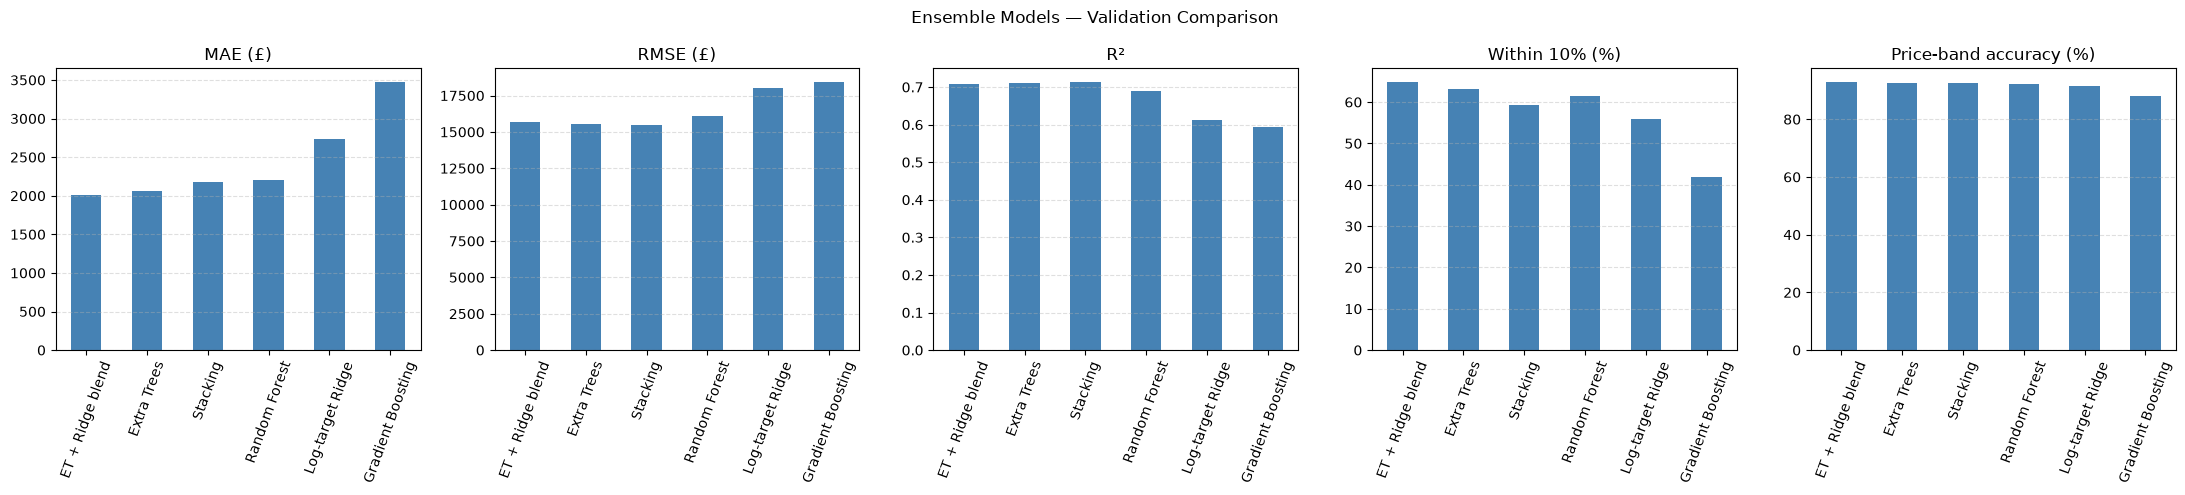

In [14]:
import matplotlib.pyplot as plt

all_predictions = {
    **predictions_by_model,
    "ET + Ridge blend": blend_val_pred,
    "Stacking": stack_pred,
}

actual = y_val.to_numpy()
price_band_cuts = [10_000, 25_000]
actual_bands = np.digitize(actual, price_band_cuts)

final_rows = []

for name, pred in all_predictions.items():
    final_rows.append({
        "Model": name,
        "MAE (£)": mean_absolute_error(actual, pred),
        "RMSE (£)": np.sqrt(mean_squared_error(actual, pred)),
        "R²": r2_score(actual, pred),
        "Within 10% (%)": 100 * np.mean(
            np.abs(actual - pred) <= 0.10 * actual
        ),
        "Price-band accuracy (%)": 100 * np.mean(
            np.digitize(pred, price_band_cuts) == actual_bands
        ),
    })

final_results = (
    pd.DataFrame(final_rows)
      .set_index("Model")
      .sort_values("MAE (£)")
)

display(final_results.round(2))

# Visual comparison of all five metrics
metrics = [
    "MAE (£)",
    "RMSE (£)",
    "R²",
    "Within 10% (%)",
    "Price-band accuracy (%)",
]

fig, axes = plt.subplots(1, len(metrics), figsize=(22, 5))

for ax, metric in zip(axes, metrics):
    final_results[metric].plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=70)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.suptitle("Ensemble Models — Validation Comparison")
plt.tight_layout()
plt.show()

[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.0s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.0s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.0s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.0s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.0s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.0s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]

,Feature,MAE increase (£)
7,power_hp,2373.99
4,reg_year,2222.67
20,vehicle_age,2070.73
3,mileage_miles,1793.37
13,drivetrain,1385.42
27,engine_size_l,1318.44
14,emission_class,1253.66
0,make,1202.36
6,transmission,1041.74
1,model,630.86


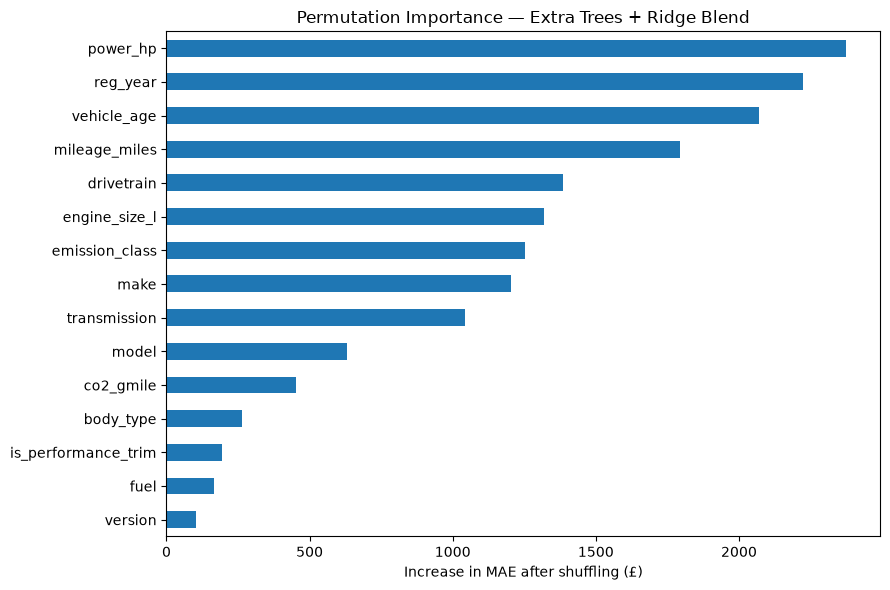

In [15]:
# Permutation importance for the selected Extra Trees + Ridge blend
rng = np.random.default_rng(42)

sample_idx = X_val.sample(
    n=min(3000, len(X_val)),
    random_state=42
).index

X_perm = X_val.loc[sample_idx].copy()
y_perm = y_val.loc[sample_idx].to_numpy()

baseline_pred = (
    best_et_weight * extra_trees.predict(X_perm)
    + best_ridge_weight * log_ridge.predict(X_perm)
)
baseline_mae = mean_absolute_error(y_perm, baseline_pred)

importance_rows = []

for col in X_perm.columns:
    shuffled_X = X_perm.copy()
    shuffled_X[col] = rng.permutation(shuffled_X[col].to_numpy())

    shuffled_pred = (
        best_et_weight * extra_trees.predict(shuffled_X)
        + best_ridge_weight * log_ridge.predict(shuffled_X)
    )

    shuffled_mae = mean_absolute_error(y_perm, shuffled_pred)

    importance_rows.append({
        "Feature": col,
        "MAE increase (£)": shuffled_mae - baseline_mae
    })

importance_df = (
    pd.DataFrame(importance_rows)
      .sort_values("MAE increase (£)", ascending=False)
)

display(importance_df.round(2))

importance_df.head(15).sort_values("MAE increase (£)").plot(
    x="Feature",
    y="MAE increase (£)",
    kind="barh",
    figsize=(9, 6),
    legend=False,
    title="Permutation Importance — Extra Trees + Ridge Blend"
)

plt.xlabel("Increase in MAE after shuffling (£)")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [16]:
from sklearn.base import clone

print(f"Refitting selected models on all {len(X_train):,} training rows...")

start = perf_counter()
final_extra_trees = clone(extra_trees)
final_extra_trees.fit(X_train, y_train)
print(f"Extra Trees fit time: {(perf_counter() - start) / 60:.1f} minutes")

start = perf_counter()
final_log_ridge = clone(log_ridge)
final_log_ridge.fit(X_train, y_train)
print(f"Log-target Ridge fit time: {(perf_counter() - start) / 60:.1f} minutes")

# Keep the blend weights selected earlier
final_blend_pred = (
    best_et_weight * final_extra_trees.predict(X_val)
    + best_ridge_weight * final_log_ridge.predict(X_val)
)
final_blend_pred = np.maximum(final_blend_pred, 0)

print("\nRefitted blend validation results")
print("MAE (£):",
      round(mean_absolute_error(y_val, final_blend_pred), 2))
print("RMSE (£):",
      round(np.sqrt(mean_squared_error(y_val, final_blend_pred)), 2))
print("R²:",
      round(r2_score(y_val, final_blend_pred), 4))

Refitting selected models on all 289,268 training rows...


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed: 16.7min finished


Extra Trees fit time: 16.8 minutes
Log-target Ridge fit time: 0.1 minutes


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.1s finished



Refitted blend validation results
MAE (£): 1601.81
RMSE (£): 14623.42
R²: 0.7447


In [17]:
final_et_pred = final_extra_trees.predict(X_val)
final_ridge_pred = final_log_ridge.predict(X_val)

final_predictions = {
    "Extra Trees": final_et_pred,
    "Log-target Ridge": final_ridge_pred,
    "Extra Trees + Ridge blend": final_blend_pred,
}

actual = y_val.to_numpy()
price_band_cuts = [10_000, 25_000]
actual_bands = np.digitize(actual, price_band_cuts)

rows = []

for name, pred in final_predictions.items():
    rows.append({
        "Model": name,
        "MAE (£)": mean_absolute_error(actual, pred),
        "RMSE (£)": np.sqrt(mean_squared_error(actual, pred)),
        "R²": r2_score(actual, pred),
        "Within 10% (%)": 100 * np.mean(
            np.abs(actual - pred) <= 0.10 * actual
        ),
        "Price-band accuracy (%)": 100 * np.mean(
            np.digitize(pred, price_band_cuts) == actual_bands
        ),
    })

final_comparison = (
    pd.DataFrame(rows)
      .set_index("Model")
      .sort_values("MAE (£)")
)

display(final_comparison.round(3))

[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.2s finished


,MAE (£),RMSE (£),R²,Within 10% (%),Price-band accuracy (%)
Model,,,,,
Extra Trees + Ridge blend,1601.808,14623.418,0.745,71.634,94.088
Extra Trees,1643.250,14517.073,0.748,69.697,93.711
Log-target Ridge,2212.777,16573.837,0.672,64.853,93.021


In [18]:
# Select the weight using the separate blend-tuning sample.
# These predictions are from models that were not trained on X_blend.
blend_actual = y_blend.to_numpy()
weight_rows = []

for et_weight in np.linspace(0, 1, 21):
    ridge_weight = 1 - et_weight

    candidate_pred = (
        et_weight * et_blend_pred
        + ridge_weight * ridge_blend_pred
    )

    weight_rows.append({
        "Extra Trees weight": et_weight,
        "Ridge weight": ridge_weight,
        "Within 10% (%)": 100 * np.mean(
            np.abs(blend_actual - candidate_pred) <= 0.10 * blend_actual
        ),
        "Tuning MAE (£)": mean_absolute_error(blend_actual, candidate_pred)
    })

weight_tuning_results = pd.DataFrame(weight_rows).sort_values(
    ["Within 10% (%)", "Tuning MAE (£)"],
    ascending=[False, True]
)

display(weight_tuning_results.round(3))

best_et_weight = float(
    weight_tuning_results.iloc[0]["Extra Trees weight"]
)
best_ridge_weight = 1 - best_et_weight

print(f"Selected weights: Extra Trees={best_et_weight:.2f}, "
      f"Ridge={best_ridge_weight:.2f}")

# Apply the selected weights to the models refitted on all training rows.
final_et_pred = final_extra_trees.predict(X_val)
final_ridge_pred = final_log_ridge.predict(X_val)

final_blend_pred = (
    best_et_weight * final_et_pred
    + best_ridge_weight * final_ridge_pred
)
final_blend_pred = np.maximum(final_blend_pred, 0)

actual = y_val.to_numpy()

print("\nValidation results with within-10%-tuned weights")
print("Within 10% (%):",
      round(100 * np.mean(
          np.abs(actual - final_blend_pred) <= 0.10 * actual
      ), 3))
print("MAE (£):",
      round(mean_absolute_error(actual, final_blend_pred), 2))
print("RMSE (£):",
      round(np.sqrt(mean_squared_error(actual, final_blend_pred)), 2))

,Extra Trees weight,Ridge weight,Within 10% (%),Tuning MAE (£)
14,0.70,0.30,65.155,1898.854
13,0.65,0.35,64.945,1921.567
15,0.75,0.25,64.925,1882.759
16,0.80,0.20,64.830,1873.539
17,0.85,0.15,64.715,1870.824
12,0.60,0.40,64.585,1949.700
11,0.55,0.45,64.295,1982.550
18,0.90,0.10,64.175,1877.659
10,0.50,0.50,63.855,2020.241
19,0.95,0.05,63.490,1891.459


Selected weights: Extra Trees=0.70, Ridge=0.30


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.3s finished



Validation results with within-10%-tuned weights
Within 10% (%): 71.938
MAE (£): 1620.81
RMSE (£): 14738.07


In [19]:
# Make a new tuning sample that neither the models nor weight selection used
unused_for_model_tuning = np.setdiff1d(unused_idx, blend_idx)
rng = np.random.default_rng(44)

model_tune_idx = rng.choice(
    unused_for_model_tuning,
    size=min(20_000, len(unused_for_model_tuning)),
    replace=False
)

X_model_tune = X_train.iloc[model_tune_idx]
y_model_tune = y_train.iloc[model_tune_idx]
y_model_tune_array = y_model_tune.to_numpy()

# Small search around the current Extra Trees settings
extra_configs = [
    {"max_depth": 24, "min_samples_leaf": 2, "max_features": 0.7},  # Current
    {"max_depth": 24, "min_samples_leaf": 1, "max_features": 0.7},
    {"max_depth": 30, "min_samples_leaf": 2, "max_features": 0.7},
    {"max_depth": 24, "min_samples_leaf": 2, "max_features": 0.5},
]

tuning_rows = []

for config in extra_configs:
    candidate = clone(extra_trees).set_params(
        regressor__model__n_estimators=20,
        regressor__model__verbose=0,
        **{
            f"regressor__model__{key}": value
            for key, value in config.items()
        }
    )

    print("Testing:", config)
    candidate.fit(X_fit, y_fit)
    candidate_pred = candidate.predict(X_model_tune)

    tuning_rows.append({
        **config,
        "Within 10% (%)": 100 * np.mean(
            np.abs(y_model_tune_array - candidate_pred)
            <= 0.10 * y_model_tune_array
        ),
        "MAE (£)": mean_absolute_error(
            y_model_tune_array,
            candidate_pred
        )
    })

extra_tuning_results = pd.DataFrame(tuning_rows)
display(
    extra_tuning_results
      .sort_values(["Within 10% (%)", "MAE (£)"],
                   ascending=[False, True])
      .round(3)
)

best_config_idx = extra_tuning_results.sort_values(
    ["Within 10% (%)", "MAE (£)"],
    ascending=[False, True]
).index[0]

best_extra_settings = extra_configs[best_config_idx]
print("Selected Extra Trees settings:", best_extra_settings)

Testing: {'max_depth': 24, 'min_samples_leaf': 2, 'max_features': 0.7}
Testing: {'max_depth': 24, 'min_samples_leaf': 1, 'max_features': 0.7}
Testing: {'max_depth': 30, 'min_samples_leaf': 2, 'max_features': 0.7}
Testing: {'max_depth': 24, 'min_samples_leaf': 2, 'max_features': 0.5}


,max_depth,min_samples_leaf,max_features,Within 10% (%),MAE (£)
2,30,2,0.7,64.130,2278.244
0,24,2,0.7,63.100,2332.043
3,24,2,0.5,62.765,2349.830
1,24,1,0.7,62.735,2317.408


Selected Extra Trees settings: {'max_depth': 30, 'min_samples_leaf': 2, 'max_features': 0.7}


In [20]:
tuned_extra_trees_small = clone(extra_trees).set_params(
    regressor__model__max_depth=best_extra_settings["max_depth"],
    regressor__model__min_samples_leaf=best_extra_settings["min_samples_leaf"],
    regressor__model__max_features=best_extra_settings["max_features"],
    regressor__model__n_estimators=20,
    regressor__model__verbose=0
)

print(f"Fitting selected Extra Trees settings on {len(X_fit):,} rows...")
start = perf_counter()
tuned_extra_trees_small.fit(X_fit, y_fit)
print(f"Fit time: {(perf_counter() - start) / 60:.1f} minutes")

# These predictions are on rows the models did not train on
tuned_et_blend_pred = tuned_extra_trees_small.predict(X_blend)

blend_actual = y_blend.to_numpy()
weight_rows = []

for et_weight in np.linspace(0, 1, 21):
    ridge_weight = 1 - et_weight
    candidate_pred = (
        et_weight * tuned_et_blend_pred
        + ridge_weight * ridge_blend_pred
    )

    weight_rows.append({
        "Extra Trees weight": et_weight,
        "Ridge weight": ridge_weight,
        "Within 10% (%)": 100 * np.mean(
            np.abs(blend_actual - candidate_pred)
            <= 0.10 * blend_actual
        ),
        "Tuning MAE (£)": mean_absolute_error(
            blend_actual, candidate_pred
        )
    })

weight_tuning_results = pd.DataFrame(weight_rows).sort_values(
    ["Within 10% (%)", "Tuning MAE (£)"],
    ascending=[False, True]
)

display(weight_tuning_results.round(3))

best_et_weight = float(
    weight_tuning_results.iloc[0]["Extra Trees weight"]
)
best_ridge_weight = 1 - best_et_weight

print(f"Selected weights: Extra Trees={best_et_weight:.2f}, "
      f"Ridge={best_ridge_weight:.2f}")

Fitting selected Extra Trees settings on 60,000 rows...
Fit time: 1.3 minutes


,Extra Trees weight,Ridge weight,Within 10% (%),Tuning MAE (£)
14,0.70,0.30,65.455,1874.976
16,0.80,0.20,65.435,1843.621
15,0.75,0.25,65.380,1855.049
17,0.85,0.15,65.235,1839.684
13,0.65,0.35,65.170,1899.725
18,0.90,0.10,64.960,1844.990
12,0.60,0.40,64.835,1929.897
19,0.95,0.05,64.615,1858.398
11,0.55,0.45,64.555,1966.257
20,1.00,0.00,64.085,1881.885


Selected weights: Extra Trees=0.70, Ridge=0.30


In [21]:
final_extra_trees_depth30 = clone(extra_trees).set_params(
    regressor__model__max_depth=best_extra_settings["max_depth"],
    regressor__model__min_samples_leaf=best_extra_settings["min_samples_leaf"],
    regressor__model__max_features=best_extra_settings["max_features"],
    regressor__model__n_estimators=20,
    regressor__model__verbose=1
)

print(f"Fitting depth-{best_extra_settings['max_depth']} Extra Trees "
      f"on all {len(X_train):,} training rows...")
start = perf_counter()
final_extra_trees_depth30.fit(X_train, y_train)
print(f"Fit time: {(perf_counter() - start) / 60:.1f} minutes")

tuned_et_val_pred = final_extra_trees_depth30.predict(X_val)
ridge_val_pred = final_log_ridge.predict(X_val)

tuned_blend_val_pred = (
    best_et_weight * tuned_et_val_pred
    + best_ridge_weight * ridge_val_pred
)
tuned_blend_val_pred = np.maximum(tuned_blend_val_pred, 0)

actual = y_val.to_numpy()

print("\nUpdated blend validation results")
print("Within 10% (%):",
      round(100 * np.mean(
          np.abs(actual - tuned_blend_val_pred) <= 0.10 * actual
      ), 3))
print("MAE (£):",
      round(mean_absolute_error(actual, tuned_blend_val_pred), 2))
print("RMSE (£):",
      round(np.sqrt(mean_squared_error(actual, tuned_blend_val_pred)), 2))
print("R²:",
      round(r2_score(actual, tuned_blend_val_pred), 4))

Fitting depth-30 Extra Trees on all 289,268 training rows...


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed: 18.8min finished


Fit time: 18.9 minutes


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.2s finished



Updated blend validation results
Within 10% (%): 73.682
MAE (£): 1555.26
RMSE (£): 14450.23
R²: 0.7507


In [22]:
from pathlib import Path
import joblib
import sklearn

ensemble_bundle = {
    "models": {
        "extra_trees": final_extra_trees_depth30,
        "log_target_ridge": final_log_ridge,
    },
    "weights": {
        "extra_trees": best_et_weight,
        "log_target_ridge": best_ridge_weight,
    },
    "feature_columns": X_train.columns.tolist(),
    "target": "price_gbp",
    "validation_metrics": {
        "within_10_percent": 73.682,
        "mae_gbp": 1555.26,
        "rmse_gbp": 14450.23,
        "r2": 0.7507,
    },
    "training_rows": len(X_train),
    "sklearn_version": sklearn.__version__,
}

model_path = Path("used_car_ensemble.joblib")
joblib.dump(ensemble_bundle, model_path, compress=3)

print(f"Saved ensemble to: {model_path.resolve()}")

Saved ensemble to: C:\Users\baidm\OneDrive\Desktop\ml project\ML_Project\used_car_ensemble.joblib


In [23]:
import joblib
import numpy as np
import pandas as pd

loaded_bundle = joblib.load("used_car_ensemble.joblib")

saved_et_pred = loaded_bundle["models"]["extra_trees"].predict(
    X_val[loaded_bundle["feature_columns"]]
)
saved_ridge_pred = loaded_bundle["models"]["log_target_ridge"].predict(
    X_val[loaded_bundle["feature_columns"]]
)

saved_blend_pred = (
    loaded_bundle["weights"]["extra_trees"] * saved_et_pred
    + loaded_bundle["weights"]["log_target_ridge"] * saved_ridge_pred
)
saved_blend_pred = np.maximum(saved_blend_pred, 0)

print(
    "Largest difference from the in-memory predictions (£):",
    round(np.max(np.abs(saved_blend_pred - tuned_blend_val_pred)), 8)
)

display(pd.DataFrame({
    "Actual price (£)": y_val.iloc[:5].to_numpy(),
    "Saved model prediction (£)": saved_blend_pred[:5].round(2),
    "Absolute error (£)": np.abs(
        y_val.iloc[:5].to_numpy() - saved_blend_pred[:5]
    ).round(2),
}))


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.6s finished


Largest difference from the in-memory predictions (£): 0.0


,Actual price (£),Saved model prediction (£),Absolute error (£)
0,26499,27471.46,972.46
1,26900,27432.15,532.15
2,17870,18032.01,162.01
3,43950,38947.18,5002.82
4,27995,28057.47,62.47


In [24]:
def predict_car_prices(new_cars):
    required_columns = loaded_bundle["feature_columns"]
    missing_columns = [
        col for col in required_columns
        if col not in new_cars.columns
    ]

    if missing_columns:
        raise ValueError(f"Missing required columns: {missing_columns}")

    car_features = new_cars[required_columns].copy()

    et_estimates = loaded_bundle["models"]["extra_trees"].predict(car_features)
    ridge_estimates = loaded_bundle["models"]["log_target_ridge"].predict(
        car_features
    )

    weights = loaded_bundle["weights"]
    ensemble_estimates = (
        weights["extra_trees"] * et_estimates
        + weights["log_target_ridge"] * ridge_estimates
    )

    return pd.DataFrame({
        "Extra Trees estimate (£)": et_estimates.round(2),
        "Ridge estimate (£)": ridge_estimates.round(2),
        "Ensemble estimate (£)": np.maximum(ensemble_estimates, 0).round(2),
    }, index=new_cars.index)


# Try it on five validation listings
display(predict_car_prices(X_val.head(5)))

[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.0s finished


,Extra Trees estimate (£),Ridge estimate (£),Ensemble estimate (£)
6,27716.80,26899.00,27471.46
12,27800.33,26573.08,27432.15
13,18666.86,16550.69,18032.01
18,39686.66,37221.71,38947.18
24,28527.62,26960.47,28057.47


In [25]:
# Silence per-tree progress messages
loaded_bundle["models"]["extra_trees"].set_params(
    regressor__model__verbose=0
)

def predict_car_prices_fast(new_cars):
    required = loaded_bundle["feature_columns"]
    missing = [col for col in required if col not in new_cars.columns]

    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    features = new_cars[required]
    weights = loaded_bundle["weights"]

    et_pred = loaded_bundle["models"]["extra_trees"].predict(features)
    ridge_pred = loaded_bundle["models"]["log_target_ridge"].predict(features)

    prediction = (
        weights["extra_trees"] * et_pred
        + weights["log_target_ridge"] * ridge_pred
    )

    return pd.Series(
        np.maximum(prediction, 0).round(2),
        index=new_cars.index,
        name="Estimated price (£)"
    )

display(predict_car_prices_fast(X_val.head(5)))

[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.0s finished


6     27471.46
12    27432.15
13    18032.01
18    38947.18
24    28057.47
Name: Estimated price (£), dtype: float64

In [26]:
import joblib
import sklearn

ensemble_bundle = {
    "models": {
        "extra_trees": final_extra_trees_depth30,
        "log_target_ridge": final_log_ridge,
    },
    "weights": {
        "extra_trees": best_et_weight,       # 0.70
        "log_target_ridge": best_ridge_weight,  # 0.30
    },
    "feature_columns": X_train.columns.tolist(),
    "target": "price_gbp",
    "extra_trees_settings": best_extra_settings,
    "validation_metrics": {
        "within_10_percent": 73.682,
        "mae_gbp": 1555.26,
        "rmse_gbp": 14450.23,
        "r2": 0.7507,
    },
    "training_rows": len(X_train),
    "sklearn_version": sklearn.__version__,
}

joblib.dump(ensemble_bundle, "used_car_ensemble.joblib", compress=3)
print("Updated used_car_ensemble.joblib with the depth-30, 70/30 blend.")

Updated used_car_ensemble.joblib with the depth-30, 70/30 blend.


In [27]:
loaded_bundle = joblib.load("used_car_ensemble.joblib")

# Silence Extra Trees progress messages during prediction
loaded_bundle["models"]["extra_trees"].set_params(
    regressor__model__verbose=0
)

features = X_val[loaded_bundle["feature_columns"]]

et_pred_saved = loaded_bundle["models"]["extra_trees"].predict(features)
ridge_pred_saved = loaded_bundle["models"]["log_target_ridge"].predict(features)

weights = loaded_bundle["weights"]
saved_prediction = np.maximum(
    weights["extra_trees"] * et_pred_saved
    + weights["log_target_ridge"] * ridge_pred_saved,
    0
)

print(
    "Largest difference from the final in-memory blend (£):",
    round(np.max(np.abs(saved_prediction - tuned_blend_val_pred)), 8)
)

display(pd.DataFrame({
    "Actual price (£)": y_val.iloc[:5].to_numpy(),
    "Final ensemble estimate (£)": saved_prediction[:5].round(2),
}, index=y_val.index[:5]))

[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    0.5s finished


Largest difference from the final in-memory blend (£): 0.0


,Actual price (£),Final ensemble estimate (£)
6,26499,27471.46
12,26900,27432.15
13,17870,18032.01
18,43950,38947.18
24,27995,28057.47


In [28]:
print("Saved blend weights:", loaded_bundle["weights"])
print(
    "Saved Extra Trees max_depth:",
    loaded_bundle["models"]["extra_trees"]
        .get_params()["regressor__model__max_depth"]
)
print(
    "Largest difference from final in-memory blend (£):",
    round(np.max(np.abs(saved_prediction - tuned_blend_val_pred)), 8)
)

Saved blend weights: {'extra_trees': 0.7000000000000001, 'log_target_ridge': 0.29999999999999993}
Saved Extra Trees max_depth: 30
Largest difference from final in-memory blend (£): 0.0


In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

actual = y_val.to_numpy()
predicted = tuned_blend_val_pred

within_10 = np.abs(actual - predicted) <= 0.10 * actual
within_10_count = within_10.sum()
within_10_percent = 100 * within_10.mean()

print(
    f"Within 10%: {within_10_count:,} of {len(actual):,} listings "
    f"({within_10_percent:.3f}%)"
)

display(pd.DataFrame({
    "Metric": ["Within 10%", "MAE (£)", "RMSE (£)", "R²"],
    "Validation result": [
        f"{within_10_percent:.3f}%",
        f"£{mean_absolute_error(actual, predicted):,.2f}",
        f"£{np.sqrt(mean_squared_error(actual, predicted)):,.2f}",
        f"{r2_score(actual, predicted):.4f}",
    ]
}))

Within 10%: 53,288 of 72,322 listings (73.682%)


,Metric,Validation result
0,Within 10%,73.682%
1,MAE (£),"£1,555.26"
2,RMSE (£),"£14,450.23"
3,R²,0.7507
